# Redes Neurais Recorrentes (RNN) — Previsão climática com PyTorch

Neste notebook, vamos utilizar uma série temporal meteorológica real para treinar uma rede neural recorrente e prever a temperatura futura.

Usaremos o **Jena Climate Dataset**, que contém medições meteorológicas realizadas em Jena, na Alemanha. O conjunto original possui diversas variáveis registradas a cada dez minutos durante vários anos.

## Objetivo do exercício

Prever a temperatura (`T (degC)`) **6 horas à frente**, usando observações meteorológicas anteriores.

Para tornar o exercício mais rápido, vamos:
- baixar o dataset automaticamente;
- utilizar um subconjunto de variáveis meteorológicas;
- reduzir a frequência dos dados para uma observação a cada 3 horas;
- utilizar as 24 observações anteriores (72 horas) para prever a temperatura 6 horas à frente;
- treinar uma LSTM com PyTorch;
- avaliar o modelo com MAE e RMSE;
- comparar visualmente as temperaturas reais e previstas.

A divisão entre treino, validação e teste será cronológica. Em séries temporais, não devemos embaralhar a série antes de fazer essa divisão, pois isso pode permitir que o modelo aprenda com informações do futuro.

## 1. Importações e configuração

O notebook utiliza bibliotecas comuns de ciência de dados e PyTorch. A execução seleciona CUDA quando disponível; caso contrário, usa a CPU.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from torch import Tensor, nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

print(f"Dispositivo: {device}")

Dispositivo: cpu


## 2. Download e leitura do dataset

O arquivo compactado é baixado somente se ainda não existir no diretório `data`. O download pode levar alguns instantes, pois o arquivo contém vários anos de medições.

Fonte do dataset: [Jena Climate — tutorial de séries temporais do TensorFlow](https://www.tensorflow.org/tutorials/structured_data/time_series).

In [2]:
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "jena_climate_2009_2016.csv.zip"
csv_path = data_dir / "jena_climate_2009_2016.csv"

dataset_url = (
    "https://storage.googleapis.com/"
    "tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
)

if not csv_path.exists():
    if not zip_path.exists():
        print("Baixando o dataset Jena Climate...")
        urlretrieve(dataset_url, zip_path)

    print("Extraindo o arquivo CSV...")
    with ZipFile(zip_path) as archive:
        archive.extractall(data_dir)

df = pd.read_csv(csv_path)

print(f"Dimensões originais: {df.shape}")
display(df.head())

Dimensões originais: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


## 3. Seleção de variáveis e análise exploratória

Vamos utilizar algumas variáveis meteorológicas numéricas. A temperatura será o alvo da previsão, mas também será incluída nas entradas, pois os valores passados de temperatura são informações válidas para prever o futuro.

A série original tem medições a cada dez minutos. Vamos manter uma observação a cada 18 linhas, obtendo uma resolução de **3 horas**. Portanto, 24 passos de entrada representam 72 horas de histórico, e dois passos à frente correspondem a 6 horas.

In [3]:
selected_columns = [
    "T (degC)",
    "p (mbar)",
    "rh (%)",
    "VPact (mbar)",
    "rho (g/m**3)",
    "wv (m/s)",
]

missing_columns = [col for col in selected_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Colunas esperadas não encontradas: {missing_columns}")

df = df[selected_columns].copy()

# A cada 10 minutos -> a cada 3 horas (18 intervalos de 10 minutos)
df = df.iloc[::18].reset_index(drop=True)

# Garantir que os valores utilizados são numéricos e remover eventuais linhas inválidas
df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

print(f"Dimensões após seleção e redução temporal: {df.shape}")
display(df.head())

Dimensões após seleção e redução temporal: (23364, 6)


,T (degC),p (mbar),rh (%),VPact (mbar),rho (g/m**3),wv (m/s)
0,-8.02,996.52,93.3,3.11,1307.75,1.03
1,-8.84,996.87,93.5,2.92,1312.37,0.07
2,-9.59,997.81,93.2,2.74,1317.44,0.24
3,-7.71,999.79,91.3,3.12,1310.51,0.14
4,-6.77,1000.21,89.5,3.29,1306.33,2.15


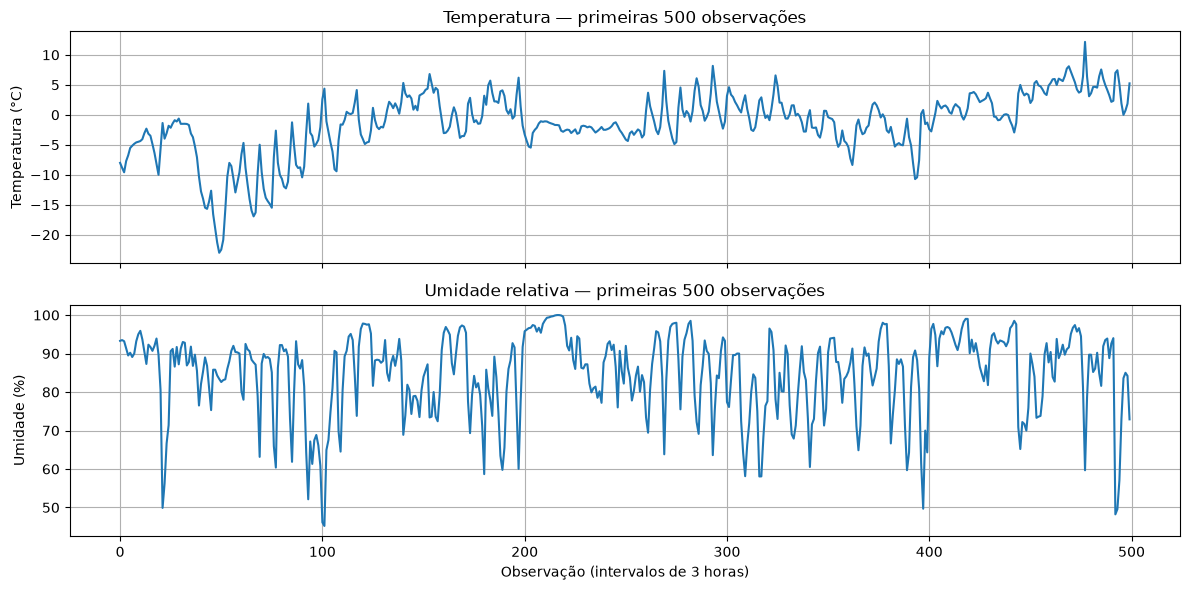

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(df["T (degC)"].iloc[:500].to_numpy())
axes[0].set_title("Temperatura — primeiras 500 observações")
axes[0].set_ylabel("Temperatura (°C)")
axes[0].grid(True)

axes[1].plot(df["rh (%)"].iloc[:500].to_numpy())
axes[1].set_title("Umidade relativa — primeiras 500 observações")
axes[1].set_xlabel("Observação (intervalos de 3 horas)")
axes[1].set_ylabel("Umidade (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 4. Divisão cronológica e normalização

Dividiremos os dados em:
- 70% iniciais para treinamento;
- 15% seguintes para validação;
- 15% finais para teste.

O `StandardScaler` será ajustado **somente com a parte de treinamento**. Isso evita utilizar estatísticas do futuro no pré-processamento.

A temperatura também é padronizada como parte das entradas. Para interpretar as previsões em graus Celsius, converteremos os resultados de volta à escala original.

In [5]:
values = df.to_numpy(dtype=np.float32)
target_column_index = df.columns.get_loc("T (degC)")

n_rows = len(values)
train_end = int(n_rows * 0.70)
val_end = int(n_rows * 0.85)

scaler = StandardScaler()
scaler.fit(values[:train_end])

scaled_values = scaler.transform(values).astype(np.float32)

temperature_mean = scaler.mean_[target_column_index]
temperature_scale = scaler.scale_[target_column_index]

print(f"Total de observações: {n_rows}")
print(f"Treinamento termina no índice: {train_end}")
print(f"Validação termina no índice: {val_end}")
print(f"Média da temperatura no treino: {temperature_mean:.2f} °C")
print(f"Desvio padrão da temperatura no treino: {temperature_scale:.2f} °C")

Total de observações: 23364
Treinamento termina no índice: 16354
Validação termina no índice: 19859
Média da temperatura no treino: 9.12 °C
Desvio padrão da temperatura no treino: 8.66 °C


## 5. Criação das sequências temporais

Cada exemplo utiliza uma janela com 24 observações passadas. Como cada observação representa 3 horas, a janela cobre 72 horas.

O alvo é a temperatura duas observações depois do último instante da janela, isto é, 6 horas no futuro.

O formato de entrada para uma RNN/LSTM do PyTorch com `batch_first=True` é:

`(batch_size, sequence_length, input_size)`

A separação dos conjuntos é feita pelo **índice temporal do alvo**. Assim, as amostras de validação e teste podem utilizar observações históricas anteriores ao início de seu intervalo como contexto, mas nunca utilizam o valor-alvo futuro como entrada.

In [6]:
sequence_length = 24
forecast_steps = 2  # 2 passos de 3 horas = previsão 6 horas à frente

def create_windows(
    data: np.ndarray,
    seq_len: int,
    horizon: int,
    target_idx: int,
    target_start: int,
    target_end: int,
) -> tuple[np.ndarray, np.ndarray]:
    x_values = []
    y_values = []

    # O alvo fica horizon passos depois do último passo da janela.
    first_target = max(seq_len - 1 + horizon, target_start)
    last_target = min(target_end, len(data))

    for target_position in range(first_target, last_target):
        window_end = target_position - horizon + 1
        window_start = window_end - seq_len

        if window_start < 0:
            continue

        x_values.append(data[window_start:window_end])
        y_values.append(data[target_position, target_idx])

    return (
        np.asarray(x_values, dtype=np.float32),
        np.asarray(y_values, dtype=np.float32).reshape(-1, 1),
    )

X_train, y_train = create_windows(
    scaled_values, sequence_length, forecast_steps,
    target_column_index, sequence_length - 1 + forecast_steps, train_end
)

X_val, y_val = create_windows(
    scaled_values, sequence_length, forecast_steps,
    target_column_index, train_end, val_end
)

X_test, y_test = create_windows(
    scaled_values, sequence_length, forecast_steps,
    target_column_index, val_end, n_rows
)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train: (16329, 24, 6) | y_train: (16329, 1)
X_val:   (3505, 24, 6) | y_val:   (3505, 1)
X_test:  (3505, 24, 6) | y_test:  (3505, 1)


## 6. Dataset e DataLoader

A classe `ClimateDataset` converte as sequências e os alvos em tensores. O `DataLoader` organiza as amostras em batches para o treinamento.

In [7]:
class ClimateDataset(Dataset):
    def __init__(self, features: np.ndarray, targets: np.ndarray) -> None:
        self.features = torch.from_numpy(features).float()
        self.targets = torch.from_numpy(targets).float()

    def __len__(self) -> int:
        return len(self.features)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        return self.features[idx], self.targets[idx]


batch_size = 128

train_dataset = ClimateDataset(X_train, y_train)
val_dataset = ClimateDataset(X_val, y_val)
test_dataset = ClimateDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## 7. Construção do modelo LSTM

A LSTM é uma arquitetura recorrente que utiliza portas para controlar o fluxo de informações ao longo da sequência. Ela costuma ser mais adequada do que uma RNN simples quando há dependências temporais mais longas.

Neste exemplo, utilizamos o estado oculto final para estimar um único valor contínuo: a temperatura futura padronizada.

In [8]:
class ClimateLSTM(nn.Module):
    def __init__(
        self,
        input_size: int,
        hidden_size: int,
        num_layers: int = 1,
        dropout: float = 0.0,
    ) -> None:
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )

        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x: Tensor) -> Tensor:
        _, (hidden, _) = self.lstm(x)
        last_hidden = hidden[-1]
        return self.output(last_hidden)


model = ClimateLSTM(
    input_size=X_train.shape[2],
    hidden_size=32,
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

ClimateLSTM(
  (lstm): LSTM(6, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


## 8. Treinamento

Em cada época, calculamos a perda média de treinamento e de validação. A validação é usada para acompanhar a generalização durante o treinamento; o conjunto de teste será reservado para a avaliação final.

O treinamento utiliza *gradient clipping* para limitar a magnitude dos gradientes, uma técnica que pode ajudar a evitar gradientes excessivamente grandes em redes recorrentes.

In [9]:
def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None,
) -> float:
    is_training = optimizer is not None
    model.train(is_training)

    losses = []

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            predictions = model(x_batch)
            loss = criterion(predictions, y_batch)

            if is_training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))


max_epochs = 10
train_losses = []
val_losses = []

for epoch in range(max_epochs):
    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    val_loss = run_epoch(model, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Época {epoch + 1:02d}/{max_epochs} | "
        f"Loss treino: {train_loss:.5f} | "
        f"Loss validação: {val_loss:.5f}"
    )

Época 01/10 | Loss treino: 0.36509 | Loss validação: 0.19691
Época 02/10 | Loss treino: 0.15605 | Loss validação: 0.11565
Época 03/10 | Loss treino: 0.09173 | Loss validação: 0.07967
Época 04/10 | Loss treino: 0.07604 | Loss validação: 0.07383
Época 05/10 | Loss treino: 0.06920 | Loss validação: 0.06828
Época 06/10 | Loss treino: 0.06547 | Loss validação: 0.06496
Época 07/10 | Loss treino: 0.06280 | Loss validação: 0.06303
Época 08/10 | Loss treino: 0.06124 | Loss validação: 0.06318
Época 09/10 | Loss treino: 0.05911 | Loss validação: 0.06174
Época 10/10 | Loss treino: 0.05834 | Loss validação: 0.06090


## 9. Visualização da perda

A perda utilizada é o erro quadrático médio (MSE) calculado na escala padronizada. Por isso, os valores não estão em graus Celsius.

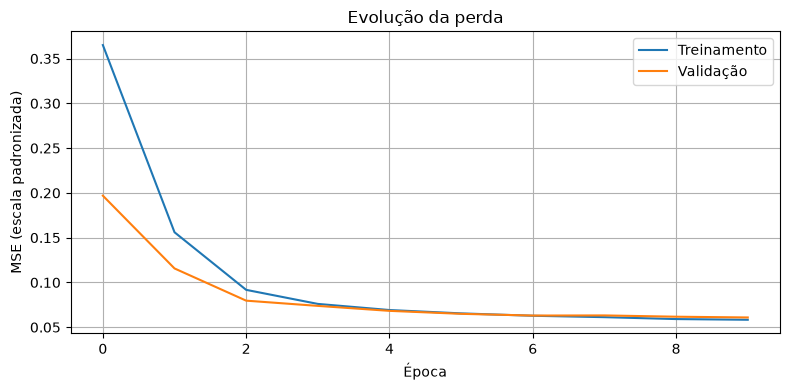

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Treinamento")
plt.plot(val_losses, label="Validação")
plt.xlabel("Época")
plt.ylabel("MSE (escala padronizada)")
plt.title("Evolução da perda")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Avaliação no conjunto de teste

Agora fazemos previsões para o período de teste, convertemos as temperaturas para graus Celsius e calculamos:
- **MAE:** erro absoluto médio, em °C;
- **RMSE:** raiz do erro quadrático médio, em °C.

Essas métricas permitem interpretar o erro em uma unidade familiar.

In [11]:
model.eval()
predictions_scaled = []
targets_scaled = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        output = model(x_batch)

        predictions_scaled.append(output.cpu().numpy())
        targets_scaled.append(y_batch.numpy())

predictions_scaled = np.concatenate(predictions_scaled).reshape(-1)
targets_scaled = np.concatenate(targets_scaled).reshape(-1)

predictions_celsius = predictions_scaled * temperature_scale + temperature_mean
targets_celsius = targets_scaled * temperature_scale + temperature_mean

mae = mean_absolute_error(targets_celsius, predictions_celsius)
rmse = np.sqrt(mean_squared_error(targets_celsius, predictions_celsius))

print(f"MAE no teste:  {mae:.3f} °C")
print(f"RMSE no teste: {rmse:.3f} °C")

MAE no teste:  1.582 °C
RMSE no teste: 2.017 °C


## 11. Temperaturas reais e previstas

O gráfico mostra uma amostra do período de teste. A previsão corresponde à temperatura 6 horas após o final da janela de entrada.

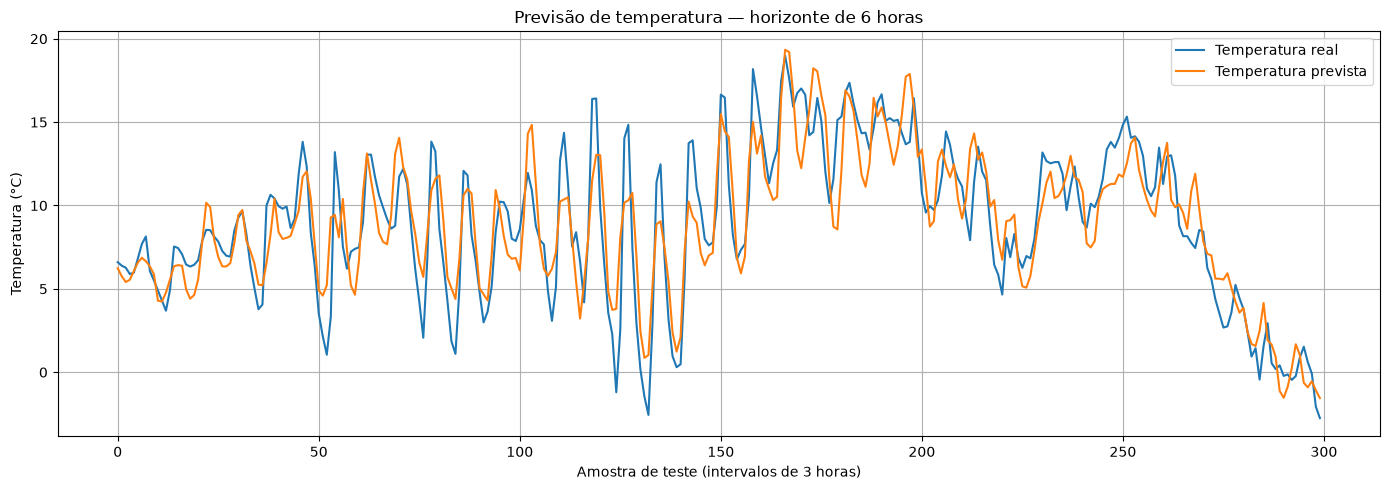

In [12]:
plot_size = min(300, len(targets_celsius))

plt.figure(figsize=(14, 5))
plt.plot(targets_celsius[:plot_size], label="Temperatura real")
plt.plot(predictions_celsius[:plot_size], label="Temperatura prevista")
plt.xlabel("Amostra de teste (intervalos de 3 horas)")
plt.ylabel("Temperatura (°C)")
plt.title("Previsão de temperatura — horizonte de 6 horas")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 12. Experimentos sugeridos

Agora você pode modificar alguns parâmetros e comparar os resultados:

- **Tamanho da janela:** altere `sequence_length` para 8, 24 ou 48 observações. Lembre-se de recriar as janelas depois da alteração.
- **Horizonte de previsão:** altere `forecast_steps`. Como cada passo representa 3 horas, `forecast_steps=1` prevê 3 horas à frente e `forecast_steps=4` prevê 12 horas à frente.
- **Tamanho do estado oculto:** teste `hidden_size=16`, `32` ou `64`.
- **Arquitetura:** compare a LSTM com `nn.GRU` ou `nn.RNN`.
- **Quantidade de épocas:** observe a diferença entre as perdas de treinamento e validação.

### Cuidados importantes

1. Não embaralhe a série antes de separar treino, validação e teste.
2. Ajuste o scaler somente com dados de treinamento.
3. Não use valores futuros como características de entrada.
4. Compare os resultados com um baseline simples, por exemplo, prever que a temperatura futura será igual à última temperatura observada.
5. O desempenho depende da configuração, e uma rede recorrente não necessariamente supera modelos simples em todas as séries temporais.

Este exercício demonstra um fluxo completo de previsão multivariada com uma LSTM. Ele é didático e não deve ser interpretado como um sistema meteorológico operacional.